# HealthPulse AI 360 — J5 : Données démographiques INSEE, structure par âge et analyse territoriale interactive

### Question de recherche
Comment la population et sa structure par âge
varient-elles entre départements français ?

### Objectifs
1. Importer les estimations démographiques INSEE.
2. Sélectionner les observations de 2024.
3. Calculer des indicateurs démographiques.
4. Effectuer une jointure avec le jeu de données J4.
5. Visualiser les résultats avec Plotly.
6. Vérifier les limites scientifiques.

In [1]:
import os

os.environ["OMP_NUM_THREADS"] = "4"
os.environ["NUMEXPR_NUM_THREADS"] = "4"

In [2]:
import pandas as pd
from pathlib import Path
import plotly.express as px                                                                                                                                                                                                                                                                                        

In [3]:
#Chemins

RACINE = Path(r"D:\Projets_Data\HealthPulse_AI_360")

RAW = RACINE / "data" / "raw" / "insee"
INTERIM = RACINE / "data" / "interim" / "demographie"
PROCESSED = RACINE / "data" / "processed"
FIGURES = RACINE / "outputs" / "figures"

for dossier in [RAW, INTERIM, PROCESSED, FIGURES]:
    dossier.mkdir(parents=True, exist_ok=True)

## 1. Télécharger et découvrir le fichier INSEE

In [4]:
#Vérifier le fichier

fichier = RAW / "estim-pop-dep-sexe-gca-1975-2026.xlsx"

print("Existe :", fichier.exists())

if fichier.exists():
    print("Taille en Ko :", round(
        fichier.stat().st_size / 1024, 1
    ))

Existe : True
Taille en Ko : 918.5


In [5]:
#Découvrir les feuilles Excel

classeur = pd.ExcelFile(fichier)

print(classeur.sheet_names)

['À savoir', '2026', '2025', '2024', '2023', '2022', '2021', '2020', '2019', '2018', '2017', '2016', '2015', '2014', '2013', '2012', '2011', '2010', '2009', '2008', '2007', '2006', '2005', '2004', '2003', '2002', '2001', '2000', '1999', '1998', '1997', '1996', '1995', '1994', '1993', '1992', '1991', '1990', '1989', '1988', '1987', '1986', '1985', '1984', '1983', '1982', '1981', '1980', '1979', '1978', '1977', '1976', '1975']


In [7]:
#Indentifier la feuille correspondant à 2024
feuilles_2024 = [
    nom for nom in classeur.sheet_names
    if "2024" in str(nom)
]

print(feuilles_2024)

['2024']


In [8]:
feuille_2024 = feuilles_2024[0]

In [9]:
#Explorer la feuille sans interpréter les en-tetes

apercu = pd.read_excel(
    fichier,
    sheet_name=feuille_2024,
    header=None,
    nrows=20
)

display(apercu)

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19
0,"Estimation de population au 1er janvier, par d...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Année 2024,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Départements,NaN,Ensemble,NaN,NaN,NaN,NaN,NaN,Hommes,NaN,NaN,NaN,NaN,NaN,Femmes,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,0 à 19 ans,20 à 39 ans,40 à 59 ans,60 à 74 ans,75 ans et plus,Total,0 à 19 ans,20 à 39 ans,40 à 59 ans,60 à 74 ans,75 ans et plus,Total,0 à 19 ans,20 à 39 ans,40 à 59 ans,60 à 74 ans,75 ans et plus,Total
5,01,Ain,171948,157049,184239,110658,61973,685867,88604,79007,91737,53423,26173,338944,83344,78042,92502,57235,35800,346923
6,02,Aisne,125001,112995,132180,97902,52999,521077,64379,57379,65748,46746,20953,255205,60622,55616,66432,51156,32046,265872
7,03,Allier,65291,62726,83537,71474,49193,332221,33684,32247,41320,33715,19509,160475,31607,30479,42217,37759,29684,171746
8,04,Alpes-de-Haute-Provence,34042,31809,43124,36658,23202,168835,17680,16043,20869,17694,9740,82026,16362,15766,22255,18964,13462,86809
9,05,Hautes-Alpes,28728,28304,37381,30629,19222,144264,14817,14332,18609,14779,7989,70526,13911,13972,18772,15850,11233,73738


## 2. Nettoyer et structurer les données INSEE

In [10]:
#Modifier l'import des données

df_brut = pd.read_excel(
    fichier,
    sheet_name=feuille_2024,
    header=None,
    skiprows=5,
    dtype={0: "string"}
)

display(df_brut.head())
print(df_brut.shape)

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19
0,01,Ain,171948.0,157049.0,184239.0,110658.0,61973.0,685867.0,88604.0,79007.0,91737.0,53423.0,26173.0,338944.0,83344.0,78042.0,92502.0,57235.0,35800.0,346923.0
1,02,Aisne,125001.0,112995.0,132180.0,97902.0,52999.0,521077.0,64379.0,57379.0,65748.0,46746.0,20953.0,255205.0,60622.0,55616.0,66432.0,51156.0,32046.0,265872.0
2,03,Allier,65291.0,62726.0,83537.0,71474.0,49193.0,332221.0,33684.0,32247.0,41320.0,33715.0,19509.0,160475.0,31607.0,30479.0,42217.0,37759.0,29684.0,171746.0
3,04,Alpes-de-Haute-Provence,34042.0,31809.0,43124.0,36658.0,23202.0,168835.0,17680.0,16043.0,20869.0,17694.0,9740.0,82026.0,16362.0,15766.0,22255.0,18964.0,13462.0,86809.0
4,05,Hautes-Alpes,28728.0,28304.0,37381.0,30629.0,19222.0,144264.0,14817.0,14332.0,18609.0,14779.0,7989.0,70526.0,13911.0,13972.0,18772.0,15850.0,11233.0,73738.0


(106, 20)


In [11]:
#Sélectionner les colonnes utiles

df_pop_2024 = df_brut.iloc[
    :, [0, 1, 5, 6, 7, 13, 19]
].copy()

In [13]:
#Attribuer des noms explicites

df_pop_2024.columns = [
    "code_dept",
    "nom_departement",
    "population_60_74_ans",
    "population_75_plus",
    "population_totale",
    "population_hommes",
    "population_femmes"
]

display(df_pop_2024.head())

,code_dept,nom_departement,population_60_74_ans,population_75_plus,population_totale,population_hommes,population_femmes
0,01,Ain,110658.0,61973.0,685867.0,338944.0,346923.0
1,02,Aisne,97902.0,52999.0,521077.0,255205.0,265872.0
2,03,Allier,71474.0,49193.0,332221.0,160475.0,171746.0
3,04,Alpes-de-Haute-Provence,36658.0,23202.0,168835.0,82026.0,86809.0
4,05,Hautes-Alpes,30629.0,19222.0,144264.0,70526.0,73738.0


In [14]:
#Harmoniser les codes départementaux

df_cog = pd.read_csv(
    RAW / "v_departement_2024.csv",
    dtype={"DEP": "string"}
)

codes_valides = set(df_cog["DEP"].dropna())

df_rejets = df_pop_2024[
    ~df_pop_2024["code_dept"].isin(codes_valides)
].copy()

df_pop_2024 = df_pop_2024[
    df_pop_2024["code_dept"].isin(codes_valides)
].copy()

print("Lignes à examiner :", len(df_rejets))
print("Départements retenus :", len(df_pop_2024))

Lignes à examiner : 5
Départements retenus : 101


## 3. Construire les indicateurs démographiques

In [17]:
#Convertir les colonnes numériques

colonnes_numeriques = [
    "population_60_74_ans",
    "population_75_plus",
    "population_totale",
    "population_hommes",
    "population_femmes"
]

for col in colonnes_numeriques:
    df_pop_2024[col] = pd.to_numeric(
        df_pop_2024[col],
        errors="coerce"
    )

In [18]:
#Vérifier les valeurs manquantes

df_pop_2024[colonnes_numeriques].isna().sum()

population_60_74_ans    0
population_75_plus      0
population_totale       0
population_hommes       0
population_femmes       0
dtype: int64

In [20]:
#Calculer la population de 60 ans ou plus
df_pop_2024["population_60_plus"] = (
    df_pop_2024["population_60_74_ans"]
    + df_pop_2024["population_75_plus"]
)

In [21]:
#Calculer la part des 60 ans ou plus

df_pop_2024["part_60_plus_pct"] = (
    df_pop_2024["population_60_plus"]
    / df_pop_2024["population_totale"]
    * 100
)

In [22]:
#Calculer la part des 75 ans ou plus

df_pop_2024["part_75_plus_pct"] = (
    df_pop_2024["population_75_plus"]
    / df_pop_2024["population_totale"]
    * 100
)

In [23]:
#Calculer la part des femmes
df_pop_2024["part_femmes_pct"] = (
    df_pop_2024["population_femmes"]
    / df_pop_2024["population_totale"]
    * 100
)

## 4. Contrôle de la qualité des données

In [24]:
print("Dimensions :", df_pop_2024.shape)

print("Départements distincts :",
      df_pop_2024["code_dept"].nunique())

print("Doublons département :",
      df_pop_2024["code_dept"].duplicated().sum())

print("Valeurs manquantes :")
print(df_pop_2024.isna().sum())

Dimensions : (101, 11)
Départements distincts : 101
Doublons département : 0
Valeurs manquantes :
code_dept               0
nom_departement         0
population_60_74_ans    0
population_75_plus      0
population_totale       0
population_hommes       0
population_femmes       0
population_60_plus      0
part_60_plus_pct        0
part_75_plus_pct        0
part_femmes_pct         0
dtype: int64


In [25]:
#Vérifier que les totaux démographiques soient cohérents

df_pop_2024["ecart_sexes"] = (
    df_pop_2024["population_totale"]
    - df_pop_2024["population_hommes"]
    - df_pop_2024["population_femmes"]
)

print(df_pop_2024["ecart_sexes"].value_counts(dropna=False))

ecart_sexes
0.0    101
Name: count, dtype: int64


## 5. Préparer la jointure CNAM-INSEE

In [26]:
#Importer le fichier de la CNAM
fichier_j4 = (
    PROCESSED / "healthpulse_diabete_dept_2024_j04.csv"
)

df_j4 = pd.read_csv(
    fichier_j4,
    dtype={"code_dept": "string"}
)

display(df_j4.head())

,annee,patho_niv1,patho_niv2,patho_niv3,top,cla_age_5,sexe,region,code_dept,ntop,npop,prev,niveau_prioritaire,libelle_classe_age,libelle_sexe,tri,effectif_num,code_region_insee,nom_departement,_merge
0,2024,Diabète,Diabète,Diabète,DIA_CAT_CAT,90-94,2,11,77,1320.0,7700,17.112,"1,2,3",de 90 à 94 ans,femmes,2.0,1320.0,11,Seine-et-Marne,both
1,2024,Diabète,Diabète,Diabète,DIA_CAT_CAT,90-94,2,11,78,1220.0,9410,12.986,"1,2,3",de 90 à 94 ans,femmes,2.0,1220.0,11,Yvelines,both
2,2024,Diabète,Diabète,Diabète,DIA_CAT_CAT,90-94,2,11,92,1280.0,10710,11.923,"1,2,3",de 90 à 94 ans,femmes,2.0,1280.0,11,Hauts-de-Seine,both
3,2024,Diabète,Diabète,Diabète,DIA_CAT_CAT,90-94,2,24,41,610.0,3640,16.630,"1,2,3",de 90 à 94 ans,femmes,2.0,610.0,24,Loir-et-Cher,both
4,2024,Diabète,Diabète,Diabète,DIA_CAT_CAT,90-94,2,27,39,390.0,2590,15.040,"1,2,3",de 90 à 94 ans,femmes,2.0,390.0,27,Jura,both


In [34]:
#Explorer les modalités
display(
    df_j4[["cla_age_5", "libelle_classe_age"]]
    .drop_duplicates()
)

display(
    df_j4[["sexe", "libelle_sexe"]]
    .drop_duplicates()
)

,cla_age_5,libelle_classe_age
0,90-94,de 90 à 94 ans
50,95et+,plus de 95 ans
144,tsage,tous âges
230,80-84,de 80 à 84 ans
233,85-89,de 85 à 89 ans
367,00-04,de 0 à 4 ans
478,05-09,de 5 à 9 ans
577,10-14,de 10 à 14 ans
677,15-19,de 15 à 19 ans
769,20-24,de 20 à 24 ans


,sexe,libelle_sexe
0,2,femmes
21,9,tous sexes
50,1,hommes


In [35]:
print(df_j4["cla_age_5"].astype("string").eq("tsage").sum())

print(df_j4["sexe"].astype("string").eq("9").sum())

303
2121


## 6. Construire la table CNAM départementale globale

In [36]:
df_cnam_total = df_j4[
    (df_j4["top"] == "DIA_CAT_CAT")
    & (df_j4["cla_age_5"] == "tsage")
    & (df_j4["sexe"].astype("string") == "9")
    & (df_j4["code_dept"].astype("string") != "999")
    & (df_j4["region"].astype("string") != "99")
].copy()

display(df_cnam_total.head())

,annee,patho_niv1,patho_niv2,patho_niv3,top,cla_age_5,sexe,region,code_dept,ntop,npop,prev,niveau_prioritaire,libelle_classe_age,libelle_sexe,tri,effectif_num,code_region_insee,nom_departement,_merge
201,2024,Diabète,Diabète,Diabète,DIA_CAT_CAT,tsage,9,4,974,89860.0,942430,9.535,"1,2,3",tous âges,tous sexes,2.0,89860.0,4,La Réunion,both
202,2024,Diabète,Diabète,Diabète,DIA_CAT_CAT,tsage,9,6,976,7770.0,127450,6.094,"1,2,3",tous âges,tous sexes,2.0,7770.0,6,Mayotte,both
203,2024,Diabète,Diabète,Diabète,DIA_CAT_CAT,tsage,9,11,77,93930.0,1450940,6.474,"1,2,3",tous âges,tous sexes,2.0,93930.0,11,Seine-et-Marne,both
204,2024,Diabète,Diabète,Diabète,DIA_CAT_CAT,tsage,9,11,78,78590.0,1487110,5.285,"1,2,3",tous âges,tous sexes,2.0,78590.0,11,Yvelines,both
205,2024,Diabète,Diabète,Diabète,DIA_CAT_CAT,tsage,9,11,91,80230.0,1331090,6.028,"1,2,3",tous âges,tous sexes,2.0,80230.0,11,Essonne,both


In [38]:
#Vérifier le nombre de départements

print("Observations :", len(df_cnam_total))

print(
    "Départements distincts :",
    df_cnam_total["code_dept"].nunique()
)

print(
    "Doublons département :",
    df_cnam_total["code_dept"].duplicated().sum()
)

Observations : 101
Départements distincts : 101
Doublons département : 0


In [39]:
#Préparer les indicateurs numériques

for col in ["ntop", "npop", "prev"]:
    df_cnam_total[col] = pd.to_numeric(
        df_cnam_total[col],
        errors="coerce"
    )

In [41]:
df_pop_2024

,code_dept,nom_departement,population_60_74_ans,population_75_plus,population_totale,population_hommes,population_femmes,population_60_plus,part_60_plus_pct,part_75_plus_pct,part_femmes_pct,ecart_sexes
0,01,Ain,110658.0,61973.0,685867.0,338944.0,346923.0,172631.0,25.169749,9.035717,50.581673,0.0
1,02,Aisne,97902.0,52999.0,521077.0,255205.0,265872.0,150901.0,28.959444,10.171050,51.023553,0.0
2,03,Allier,71474.0,49193.0,332221.0,160475.0,171746.0,120667.0,36.321304,14.807312,51.696311,0.0
3,04,Alpes-de-Haute-Provence,36658.0,23202.0,168835.0,82026.0,86809.0,59860.0,35.454734,13.742411,51.416472,0.0
4,05,Hautes-Alpes,30629.0,19222.0,144264.0,70526.0,73738.0,49851.0,34.555398,13.324183,51.113237,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...
97,971,Guadeloupe,81296.0,39570.0,383889.0,175586.0,208303.0,120866.0,31.484622,10.307667,54.261258,0.0
98,972,Martinique,81133.0,39900.0,360227.0,164733.0,195494.0,121033.0,33.599092,11.076349,54.269669,0.0
99,973,Guyane,25162.0,7415.0,296151.0,143236.0,152915.0,32577.0,11.000132,2.503790,51.634133,0.0
100,974,La Réunion,140171.0,53482.0,897613.0,427367.0,470246.0,193653.0,21.574220,5.958247,52.388502,0.0


In [42]:
#Effectuer la jointure

colonnes_pop = [
    "code_dept",
    "population_totale",
    "population_60_plus",
    "part_60_plus_pct",
    "part_75_plus_pct",
    "part_femmes_pct"
]

# Ajouter le nom du département s'il est absent de la table CNAM.
if "nom_departement" not in df_cnam_total.columns:
    colonnes_pop.insert(1, "nom_departement")

df_j5 = df_cnam_total.merge(
    df_pop_2024[colonnes_pop],
    on="code_dept",
    how="left",
    validate="one_to_one",
    indicator=False
)

display(df_j5.head())

,annee,patho_niv1,patho_niv2,patho_niv3,top,cla_age_5,sexe,region,code_dept,ntop,...,tri,effectif_num,code_region_insee,nom_departement,_merge,population_totale,population_60_plus,part_60_plus_pct,part_75_plus_pct,part_femmes_pct
0,2024,Diabète,Diabète,Diabète,DIA_CAT_CAT,tsage,9,4,974,89860.0,...,2.0,89860.0,4,La Réunion,both,897613.0,193653.0,21.574220,5.958247,52.388502
1,2024,Diabète,Diabète,Diabète,DIA_CAT_CAT,tsage,9,6,976,7770.0,...,2.0,7770.0,6,Mayotte,both,320646.0,13843.0,4.317222,0.915028,52.338092
2,2024,Diabète,Diabète,Diabète,DIA_CAT_CAT,tsage,9,11,77,93930.0,...,2.0,93930.0,11,Seine-et-Marne,both,1479706.0,317898.0,21.483862,7.238870,51.245383
3,2024,Diabète,Diabète,Diabète,DIA_CAT_CAT,tsage,9,11,78,78590.0,...,2.0,78590.0,11,Yvelines,both,1495123.0,343647.0,22.984530,8.703766,51.288891
4,2024,Diabète,Diabète,Diabète,DIA_CAT_CAT,tsage,9,11,91,80230.0,...,2.0,80230.0,11,Essonne,both,1347483.0,289728.0,21.501422,7.842696,50.876560


In [43]:
#Vérifier la granularité

assert len(df_j5) == len(df_cnam_total)

assert df_j5["code_dept"].is_unique

print("Nombre de départements :", df_j5["code_dept"].nunique())

Nombre de départements : 101


In [44]:
display(
    df_j5[
        [
            "code_dept",
            "ntop",
            "npop",
            "prev",
            "population_totale",
            "part_60_plus_pct"
        ]
    ].head()
)

,code_dept,ntop,npop,prev,population_totale,part_60_plus_pct
0,974,89860.0,942430,9.535,897613.0,21.574220
1,976,7770.0,127450,6.094,320646.0,4.317222
2,77,93930.0,1450940,6.474,1479706.0,21.483862
3,78,78590.0,1487110,5.285,1495123.0,22.984530
4,91,80230.0,1331090,6.028,1347483.0,21.501422


## 7. Analyse exploratoire et visualisations interactives

In [45]:
#Vérifier les données avant de créer les graphiques

print("Dimensions :", df_j5.shape)

print("Colonnes disponibles :")
print(df_j5.columns.tolist())

display(df_j5.head())

Dimensions : (101, 25)
Colonnes disponibles :
['annee', 'patho_niv1', 'patho_niv2', 'patho_niv3', 'top', 'cla_age_5', 'sexe', 'region', 'code_dept', 'ntop', 'npop', 'prev', 'niveau_prioritaire', 'libelle_classe_age', 'libelle_sexe', 'tri', 'effectif_num', 'code_region_insee', 'nom_departement', '_merge', 'population_totale', 'population_60_plus', 'part_60_plus_pct', 'part_75_plus_pct', 'part_femmes_pct']


,annee,patho_niv1,patho_niv2,patho_niv3,top,cla_age_5,sexe,region,code_dept,ntop,...,tri,effectif_num,code_region_insee,nom_departement,_merge,population_totale,population_60_plus,part_60_plus_pct,part_75_plus_pct,part_femmes_pct
0,2024,Diabète,Diabète,Diabète,DIA_CAT_CAT,tsage,9,4,974,89860.0,...,2.0,89860.0,4,La Réunion,both,897613.0,193653.0,21.574220,5.958247,52.388502
1,2024,Diabète,Diabète,Diabète,DIA_CAT_CAT,tsage,9,6,976,7770.0,...,2.0,7770.0,6,Mayotte,both,320646.0,13843.0,4.317222,0.915028,52.338092
2,2024,Diabète,Diabète,Diabète,DIA_CAT_CAT,tsage,9,11,77,93930.0,...,2.0,93930.0,11,Seine-et-Marne,both,1479706.0,317898.0,21.483862,7.238870,51.245383
3,2024,Diabète,Diabète,Diabète,DIA_CAT_CAT,tsage,9,11,78,78590.0,...,2.0,78590.0,11,Yvelines,both,1495123.0,343647.0,22.984530,8.703766,51.288891
4,2024,Diabète,Diabète,Diabète,DIA_CAT_CAT,tsage,9,11,91,80230.0,...,2.0,80230.0,11,Essonne,both,1347483.0,289728.0,21.501422,7.842696,50.876560


In [46]:
#Préparer les indicateurs numériques

colonnes_numeriques = [
    "ntop",
    "npop",
    "prev",
    "population_totale",
    "part_60_plus_pct",
    "part_75_plus_pct"
]

for col in colonnes_numeriques:
    df_j5[col] = pd.to_numeric(
        df_j5[col],
        errors="coerce"
    )

In [47]:
#Controler la granularité avant la visualisation

print("Départements distincts :",
      df_j5["code_dept"].nunique())

print("Doublons département :",
      df_j5["code_dept"].duplicated().sum())

print("Correspondances :")
print(df_j5["_merge"].value_counts())

Départements distincts : 101
Doublons département : 0
Correspondances :
_merge
both    101
Name: count, dtype: int64


In [48]:
#Top 15 des départements où les séniors sont les surreprésentés

import plotly.express as px

top15 = (
    df_j5
    .dropna(subset=[
        "nom_departement",
        "part_60_plus_pct"
    ])
    .nlargest(15, "part_60_plus_pct")
    .sort_values("part_60_plus_pct")
)

display(top15[
    [
        "nom_departement",
        "population_totale",
        "part_60_plus_pct"
    ]
])

,nom_departement,population_totale,part_60_plus_pct
12,Orne,273958.0,35.367100
27,Alpes-de-Haute-Provence,168835.0,35.454734
25,Ariège,156158.0,35.621614
23,Hautes-Pyrénées,231783.0,35.841283
19,Aveyron,279184.0,35.940813
94,Allier,332221.0,36.321304
17,Corrèze,241041.0,36.385511
54,Gers,192545.0,37.174167
85,Charente-Maritime,677063.0,37.179701
33,Indre,215000.0,37.515349


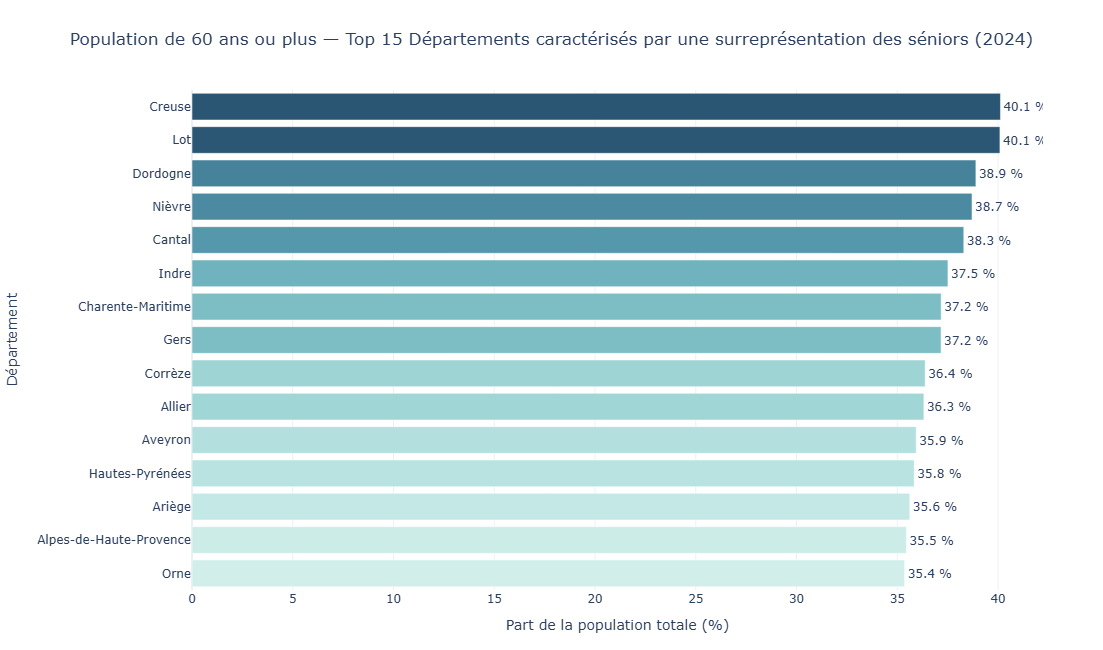

In [50]:
#Créer le graphique interactif

fig_age = px.bar(
    top15,
    x="part_60_plus_pct",
    y="nom_departement",
    orientation="h",
    color="part_60_plus_pct",
    color_continuous_scale="Teal",
    hover_name="nom_departement",
    hover_data={
        "code_dept": True,
        "population_totale": ":,.0f",
        "part_60_plus_pct": ":.1f"
    },
    text="part_60_plus_pct",
    title="Population de 60 ans ou plus — Top 15 Départements caractérisés par une surreprésentation des séniors (2024)",
    labels={
        "part_60_plus_pct": "Part de la population totale (%)",
        "nom_departement": "Département"
    },
    template="plotly_white"
)

fig_age.update_traces(
    texttemplate="%{x:.1f} %",
    textposition="outside"
)

fig_age.update_layout(
    height=650,
    title_x=0.5,
    showlegend=False,
    coloraxis_showscale=False,
    margin=dict(l=160, r=60, t=90, b=60)
)

fig_age.show()

## 7.2. Vieilissement démographique et diabète

In [55]:
#Graphique 2 : Vieillisement démographique et diabète

df_scatter = df_j5.dropna(
    subset=[
        "part_60_plus_pct",
        "prev",
        "nom_departement"
    ]
).copy()

df_scatter["region"] = df_scatter["region"].astype("str")

print("Départements exploitables :", len(df_scatter))

Départements exploitables : 101


In [62]:
df_scatter.columns

Index(['annee', 'patho_niv1', 'patho_niv2', 'patho_niv3', 'top', 'cla_age_5',
       'sexe', 'region', 'code_dept', 'ntop', 'npop', 'prev',
       'niveau_prioritaire', 'libelle_classe_age', 'libelle_sexe', 'tri',
       'effectif_num', 'code_region_insee', 'nom_departement', '_merge',
       'population_totale', 'population_60_plus', 'part_60_plus_pct',
       'part_75_plus_pct', 'part_femmes_pct'],
      dtype='object')

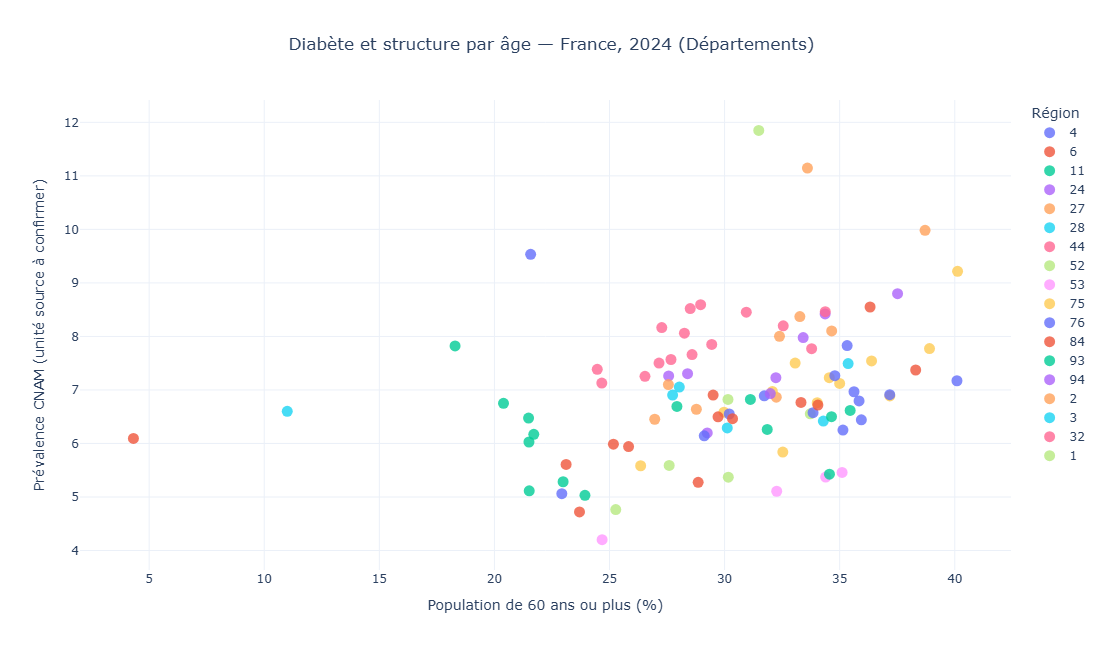

In [63]:
#Créer le nuage de points

fig_scatter = px.scatter(
    df_scatter,
    x="part_60_plus_pct",
    y="prev",
    color="region",
    hover_name="nom_departement",
    hover_data={
        "code_dept": True,
        "ntop": True,
        "population_totale": ":,.0f"
    },
    title="Diabète et structure par âge — France, 2024 (Départements)",
    labels={
        "part_60_plus_pct": "Population de 60 ans ou plus (%)",
        "prev": "Prévalence CNAM (unité source à confirmer)",
        "region": "Code région"
    },
    template="plotly_white",
    opacity=0.8
)

fig_scatter.update_traces(
    marker=dict(size=11)
)

fig_scatter.update_layout(
    height=650,
    title_x=0.5,
    legend_title_text="Région"
)

fig_scatter.show()

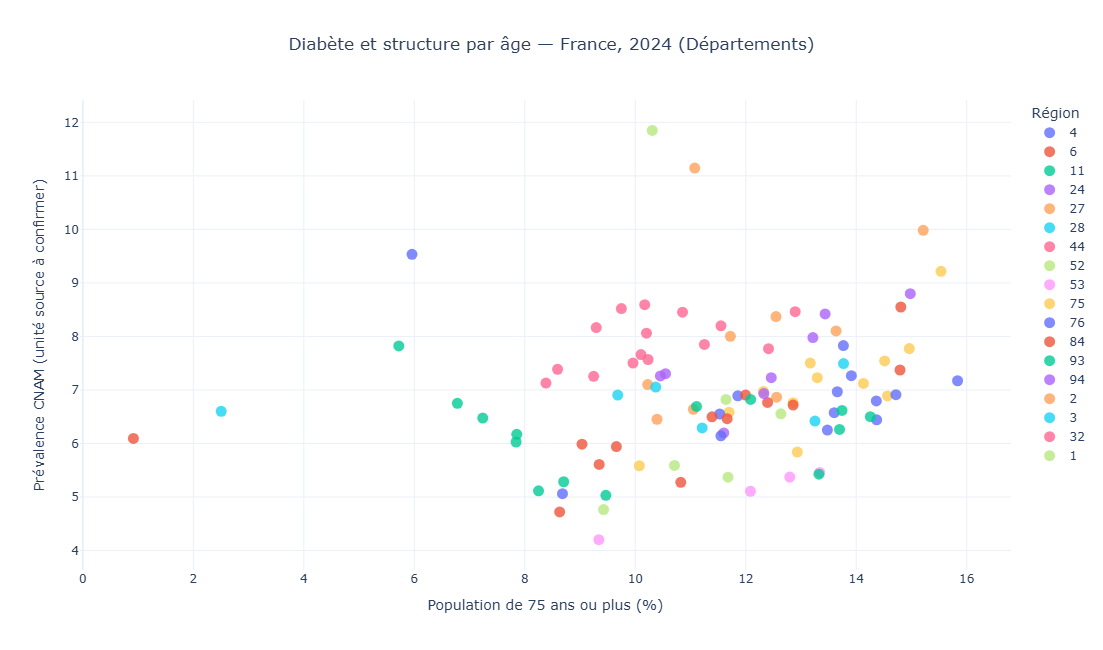

In [64]:
#Créer le nuage de points

fig_scatter_2 = px.scatter(
    df_scatter,
    x="part_75_plus_pct",
    y="prev",
    color="region",
    hover_name="nom_departement",
    hover_data={
        "code_dept": True,
        "ntop": True,
        "population_totale": ":,.0f"
    },
    title="Diabète et structure par âge — France, 2024 (Départements)",
    labels={
        "part_75_plus_pct": "Population de 75 ans ou plus (%)",
        "prev": "Prévalence CNAM (unité source à confirmer)",
        "region": "Code région"
    },
    template="plotly_white",
    opacity=0.8
)

fig_scatter_2.update_traces(
    marker=dict(size=11)
)

fig_scatter_2.update_layout(
    height=650,
    title_x=0.5,
    legend_title_text="Région"
)

fig_scatter_2.show()

## 8. Exporter les données et graphiques

In [66]:
#Préparer les dossiers de sortie

from pathlib import Path

RACINE = Path(r"D:\Projets_Data\HealthPulse_AI_360")

PROCESSED = RACINE / "data" / "processed"
INTERIM = RACINE / "data" / "interim" / "demographie"
FIGURES = RACINE / "outputs" / "figures"

for dossier in [PROCESSED, INTERIM, FIGURES]:
    dossier.mkdir(parents=True, exist_ok=True)

In [67]:
#Vérifier la base avant l'export final

assert df_j5["code_dept"].notna().all()
assert df_j5["code_dept"].is_unique

assert df_j5["population_totale"].notna().all()
assert df_j5["population_totale"].gt(0).all()

assert df_j5["part_60_plus_pct"].between(0, 100).all()

print("Contrôles de base réussis.")

Contrôles de base réussis.


In [68]:
#Enregistrer la table enrichie

df_final = df_j5.drop(
    columns=["_merge"],
    errors="ignore"
)

sortie = (
    PROCESSED
    / "healthpulse_diabete_demographie_2024_j05.csv"
)

df_final.to_csv(
    sortie,
    index=False,
    encoding="utf-8-sig"
)

print("Fichier enregistré :", sortie)

Fichier enregistré : D:\Projets_Data\HealthPulse_AI_360\data\processed\healthpulse_diabete_demographie_2024_j05.csv


In [69]:
#Exporter les 2 graphiques

fig_age.write_html(
    FIGURES / "j05_top15_population_60_plus.html",
    include_plotlyjs=True
)

fig_scatter.write_html(
    FIGURES / "j05_diabete_vieillissement.html",
    include_plotlyjs=True
)